In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Data ah load panrom
df = pd.read_csv("../Data/WA_FN-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [2]:
# Basic info
print(f"Total Employees: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")
print("\nAttrition Count:")
print(df['Attrition'].value_counts())
print("\nAttrition %:")
print(df['Attrition'].value_counts(normalize=True)*100)

Total Employees: 1470
Columns: 35

Attrition Count:
Attrition
No     1233
Yes     237
Name: count, dtype: int64

Attrition %:
Attrition
No     83.877551
Yes    16.122449
Name: proportion, dtype: float64


In [3]:
# Missing values check
df.isnull().sum().sum()

np.int64(0)

C:\Users\Admin\AppData\Local\Temp\ipykernel_22148\3961678922.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Attrition', data=df, palette='Set2')


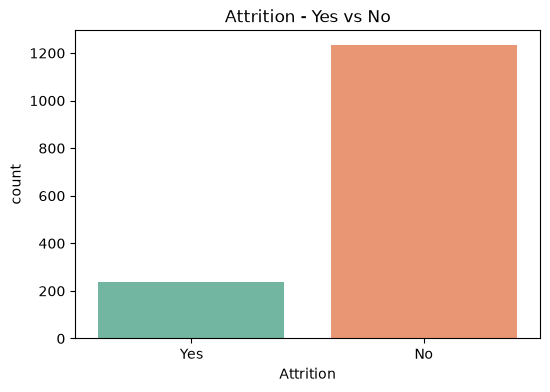

In [4]:
# Attrition Graph
plt.figure(figsize=(6,4))
sns.countplot(x='Attrition', data=df, palette='Set2')
plt.title('Attrition - Yes vs No')
plt.show()

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Thevai illatha columns ah remove
df_model = df.drop(['EmployeeCount', 'EmployeeNumber', 'Over18', 'StandardHours'], axis=1)

# Text ah number ah mathurom
le = LabelEncoder()
for col in df_model.select_dtypes(include='object').columns:
    df_model[col] = le.fit_transform(df_model[col])

X = df_model.drop('Attrition', axis=1)
y = df_model['Attrition']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f"Accuracy: {accuracy_score(y_test, y_pred)*100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

C:\Users\Admin\AppData\Local\Temp\ipykernel_22148\1196093946.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_model.select_dtypes(include='object').columns:


Accuracy: 88.10%

Classification Report:
               precision    recall  f1-score   support

           0       0.88      1.00      0.94       255
           1       0.83      0.13      0.22        39

    accuracy                           0.88       294
   macro avg       0.86      0.56      0.58       294
weighted avg       0.88      0.88      0.84       294



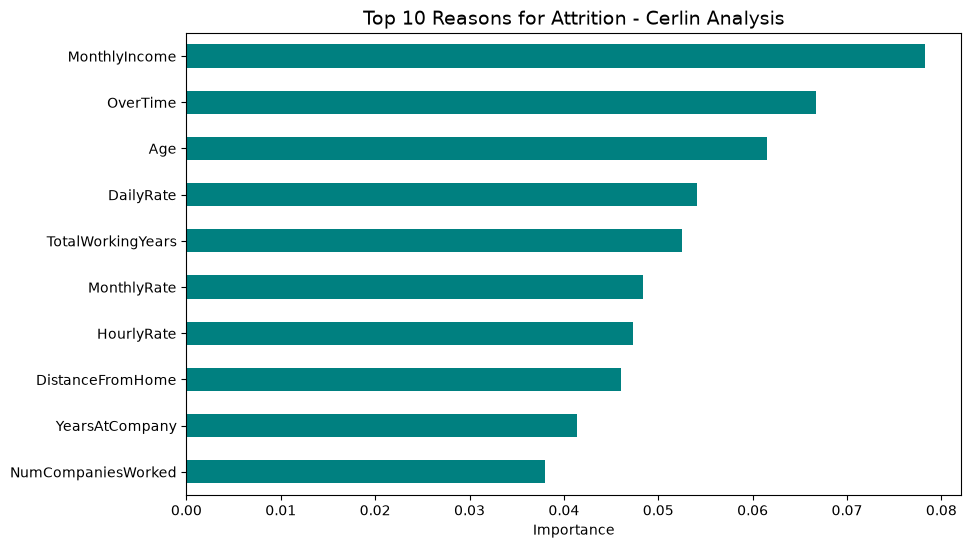

MonthlyIncome         0.078212
OverTime              0.066669
Age                   0.061569
DailyRate             0.054087
TotalWorkingYears     0.052491
MonthlyRate           0.048373
HourlyRate            0.047369
DistanceFromHome      0.045999
YearsAtCompany        0.041347
NumCompaniesWorked    0.037951
dtype: float64


In [6]:
# Top 10 Reasons for Attrition
importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10,6))
importances.head(10).plot(kind='barh', color='teal')
plt.title('Top 10 Reasons for Attrition - Cerlin Analysis', fontsize=14)
plt.gca().invert_yaxis()
plt.xlabel('Importance')
plt.show()

print(importances.head(10))